## Análisis de modelos

## Random Forest

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, roc_auc_score, accuracy_score, precision_score, confusion_matrix
from itertools import product
import os
import joblib
import mlflow


In [2]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


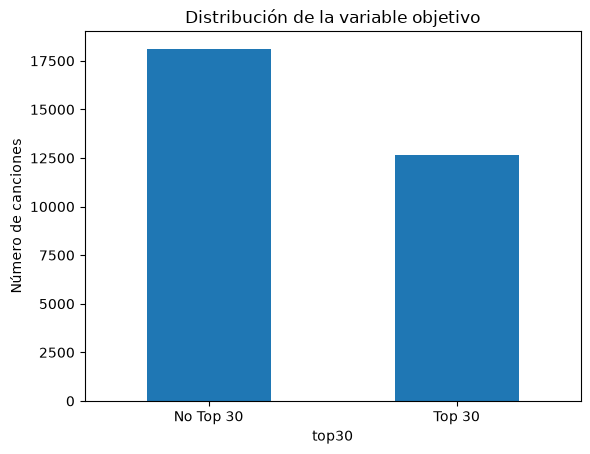

In [3]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Decimos a MLflow dónde guardar:

In [ ]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")   
mlflow.set_experiment("experimento_musica")

## Separamos train y test:

In [5]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.10, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(24923, 13) (2770, 13) (3078, 13)
En train: 41.14 % En validación:  41.16 %   en test: 41.13 %


In [6]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(24923, 13)

Columnas con nulos:
spotify_track_duration_ms    2976
spotify_track_explicit       2976
danceability                 3025
key                          3025
loudness                     3025
mode                         3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
time_signature               3025
dtype: int64


## Aplicamos el análisis en X_train

In [7]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 3025
speechiness                  3025
instrumentalness             3025
tempo                        3025
loudness                     3025
key                          3025
mode                         3025
time_signature               3025
spotify_track_duration_ms    2976
spotify_track_explicit       2976
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6020063932779248), 'speechiness': np.float64(0.08950473102566445), 'instrumentalness': np.float64(0.032657926696501964), 'tempo': np.float64(121.06935149328706), 'loudness': -8.13, 'key': np.float64(0.0), 'mode'

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_7984\3074567703.py:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(stats_global[col])


## Rellenamos nulos en X_val 

In [8]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 319
speechiness                  319
instrumentalness             319
tempo                        319
loudness                     319
key                          319
mode                         319
time_signature               319
spotify_track_duration_ms    315
spotify_track_explicit       315
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_7984\707013219.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[col] = X_val[col].fillna(stats_global[col])


## Rellenamos nulos en X_test

In [9]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 365
speechiness                  365
instrumentalness             365
tempo                        365
loudness                     365
key                          365
mode                         365
time_signature               365
spotify_track_duration_ms    359
spotify_track_explicit       359
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_7984\3823342436.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[col] = X_test[col].fillna(stats_global[col])


In [10]:
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [11]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)
cat_test = pd.DataFrame(encoder.transform(X_test[texto]), columns=nombres, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
X_test = pd.concat([X_test.drop(columns=texto), cat_test], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

['performer_"Little" Jimmy Dickens' 'performer_"Pookie" Hudson'
 'performer_"Weird Al" Yankovic' ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 11001
Nulos después del OneHotEncoder:
Train: 0
Validation: 0
Test: 0


In [12]:
def evaluar(nombre, modelo, n_boot=200, seed=42):
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)
    probs_val = modelo.predict_proba(X_val)[:, 1]

    rng = np.random.default_rng(seed)
    y_val_arr = np.asarray(y_val)
    n = len(y_val_arr)
    f1s = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        f1s.append(f1_score(y_val_arr[idx], pred_val[idx]))
    mlflow.log_metric("accuracy", accuracy_score(y_val,pred_val))
    mlflow.log_metric("precision", precision_score(y_val,pred_val))
    mlflow.log_metric("recall", recall_score(y_val,pred_val))
    mlflow.log_metric("f1", f1_score(y_val, pred_val))

    mlflow.sklearn.log_model(
    modelo,
    name=nombre,
    skops_trusted_types=["sklearn.tree._tree.Tree"]
)
    
    return {"modelo": nombre,
            "F1 val": f1_score(y_val, pred_val),
            "± F1 val": np.std(f1s),
            "recall val": recall_score(y_val, pred_val),
            "AUC val": roc_auc_score(y_val, probs_val),
            "F1 train": f1_score(y_train, pred_train)}

resultados = []

## Baseline: decir siempre la clase más frecuente

Lo calculamos a mano. Como la clase más frecuente es «no entra en el top 30», el baseline no encuentra a nadie: F1 = 0 y AUC = 0,5.

"pred_base" es el modelo más tonto posible: cualquier modelo que usemos tiene que ganarle.

In [13]:
pred_base = np.full(len(y_train), y_train.mode()[0])  


In [14]:
resultados = []
resultados.append({"modelo": "Baseline (siempre 'no')",
                   "F1 val": f1_score(y_train, pred_base), "± F1 val": np.nan,
                   "recall val": recall_score(y_train, pred_base), "AUC val": 0.5,
                   "F1 train": f1_score(y_train, pred_base)})

## Random Forest por defecto

300 árboles sin límite, cada uno con su bolsa y con sorteo de variables.

In [15]:
mlflow.end_run()
with mlflow.start_run(run_name="random_forest_default"):
    mlflow.log_param("random_state", 42)
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("n_jobs", -1)
    mlflow.log_param("max_depth", None)
    resultados.append(evaluar("Random Forest por defecto",
                            RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)))
pd.DataFrame(resultados).round(3)

2026/11/16 15:16:14 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/16 15:16:14 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (siempre 'no'),0.000,NaN,0.000,0.500,0.000
1,Random Forest por defecto,0.477,0.014,0.359,0.712,0.987


## Random Forest ajustado

In [16]:
rejilla = {
    "max_features": ["sqrt", 0.3, 0.5],
    "min_samples_leaf": [5, 10, 20, 30],
    "max_depth": [10, 15, 20],
    "max_samples": [0.7, 0.9]
}

resultados_rf = []
for mf, msl, md, ms in product(rejilla["max_features"], rejilla["min_samples_leaf"], rejilla["max_depth"], rejilla["max_samples"]):
    rf = RandomForestClassifier(n_estimators=300, max_features=mf,
                                min_samples_leaf=msl, max_depth=md, max_samples=ms, random_state=42, n_jobs=-1)
    fila = evaluar("Random_Forest_ajustado", rf)
    fila["max_features"] = mf
    fila["min_samples_leaf"] = msl
    fila["max_depth"] = md
    fila["max_samples"] = ms
    resultados_rf.append(fila)

tabla_rf = pd.DataFrame(resultados_rf).sort_values("F1 val", ascending=False)
print(tabla_rf[["modelo", "F1 val", "± F1 val", "recall val", "AUC val", "F1 train"]])

mejores = tabla_rf.iloc[0]
mejores_params = {"max_features": mejores["max_features"],
                  "min_samples_leaf": int(mejores["min_samples_leaf"]),
                  "max_depth": None if pd.isna(mejores["max_depth"]) else int(mejores["max_depth"]),
                  "max_samples": mejores["max_samples"]}
print("Mejores hiperparámetros:", mejores_params)

c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

                    modelo    F1 val  ± F1 val  recall val   AUC val  F1 train
59  Random_Forest_ajustado  0.394591  0.014113    0.281579  0.668575  0.605179
65  Random_Forest_ajustado  0.393789  0.014780    0.278070  0.668194  0.530185
52  Random_Forest_ajustado  0.389660  0.015065    0.271053  0.675374  0.636061
53  Random_Forest_ajustado  0.386009  0.014688    0.271053  0.675393  0.664741
34  Random_Forest_ajustado  0.385450  0.014902    0.264912  0.675179  0.528042
..                     ...       ...       ...         ...       ...       ...
23  Random_Forest_ajustado  0.000000  0.000000    0.000000  0.625803  0.000000
12  Random_Forest_ajustado  0.000000  0.000000    0.000000  0.640974  0.000000
13  Random_Forest_ajustado  0.000000  0.000000    0.000000  0.638523  0.000000
14  Random_Forest_ajustado  0.000000  0.000000    0.000000  0.640845  0.000000
15  Random_Forest_ajustado  0.000000  0.000000    0.000000  0.638014  0.000000

[72 rows x 6 columns]
Mejores hiperparámetros: {'ma

In [17]:
# rf_final = RandomForestClassifier(
#     n_estimators=300,
#     max_features=0.5,
#     min_samples_leaf=5,
#     max_depth=20,
#     max_samples=0.7,
#     random_state=42,
#     n_jobs=-1
# )

# # Entrenamiento del modelo
# rf_final.fit(X_train, y_train)

# # Evaluación
# fila_final = evaluar("Random Forest final", rf_final)

In [18]:
# print(fila_final)

In [19]:
# 18462 canciones para entrenar · 6154 para validar · 6155 para el test final
#                 modelo    F1 val  ± F1 val  recall val   AUC val  F1 train
# 6    RF mf=1.0, leaf=2  0.458333  0.009637    0.364929  0.671747  0.971232
# 3    RF mf=0.5, leaf=2  0.453137  0.009963    0.352291  0.675334  0.970767
# 7    RF mf=1.0, leaf=5  0.448669  0.010374    0.349526  0.670833  0.927900
# 4    RF mf=0.5, leaf=5  0.440941  0.010349    0.336888  0.674380  0.911550
# 0   RF mf=sqrt, leaf=2  0.430380  0.011240    0.295419  0.701309  0.534073
# 8   RF mf=1.0, leaf=10  0.426350  0.010474    0.319510  0.669248  0.818425
# 5   RF mf=0.5, leaf=10  0.415115  0.010879    0.303712  0.671162  0.782615
# 1   RF mf=sqrt, leaf=5  0.338413  0.011370    0.210506  0.679991  0.357985
# 2  RF mf=sqrt, leaf=10  0.179688  0.010277    0.099921  0.661354  0.205313
# Mejores hiperparámetros: {'max_features': 1.0, 'min_samples_leaf': 2}

In [21]:
mlflow.end_run()
with mlflow.start_run(run_name="random_forest_ajustado"):

    rf_final = RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        **mejores_params
    )

    mlflow.log_param("random_state", 42)
    mlflow.log_param("n_jobs", -1)
    mlflow.log_params(mejores_params)

    rf_final.fit(X_train, y_train)

    resultados.append(evaluar("Random forest ajustado", rf_final))

## Realizamos la matriz de confusión con train

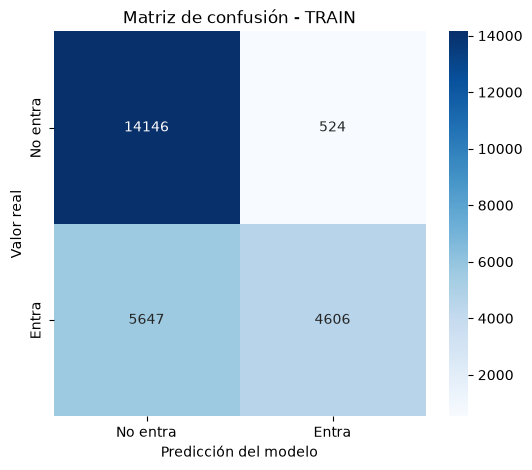

In [ ]:
probabilidades = rf_final.predict(X_train).flatten()

predicciones = (probabilidades >= 0.5).astype(int)

matriz = confusion_matrix(y_train, predicciones)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No entra", "Entra"],
    yticklabels=["No entra", "Entra"]
)

plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - TRAIN")

plt.show()

In [ ]:
pred_train = rf_final.predict(X_train)     
prob_train = rf_final.predict_proba(X_train)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

In [ ]:
pred_train = rf_final.predict(X_val)     
prob_train = rf_final.predict_proba(X_val)[:, 1]  

cm = confusion_matrix(y_val, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (validación)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_val, pred_train):.3f}   '
      f'precision {precision_score(y_val, pred_train):.3f}   '
      f'recall {recall_score(y_val, pred_train):.3f}   F1 {f1_score(y_val, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_val, prob_train), 3))

## Variables más importantes en el Random Forest

C:\Users\Xabier.garcia\AppData\Local\Temp\ipykernel_9080\1447422808.py:3: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


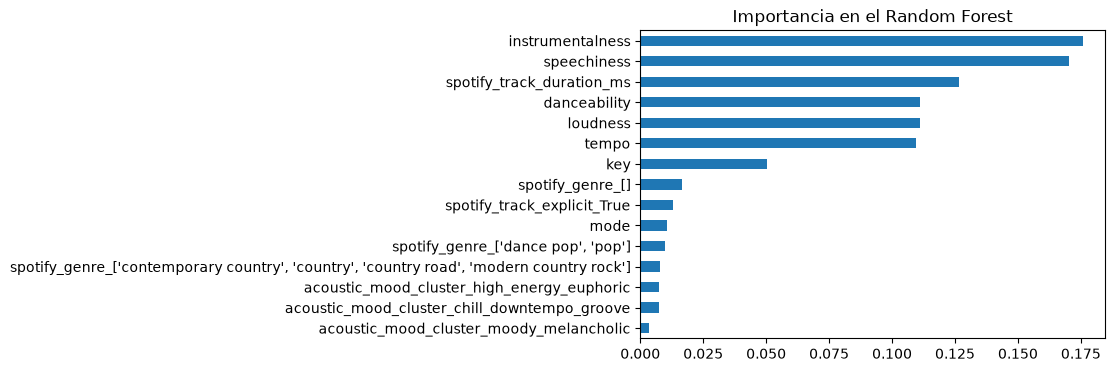

In [ ]:
importancias = pd.Series(rf_final.feature_importances_, index=X_train.columns).sort_values()
importancias.tail(15).plot.barh(figsize=(6, 4), title="Importancia en el Random Forest")
plt.tight_layout(); plt.show()

## Tabla comparativa

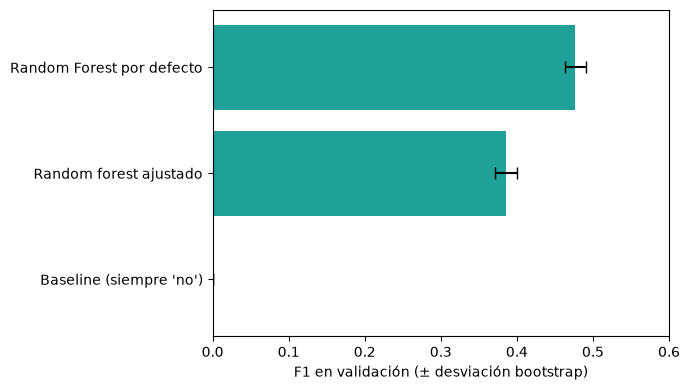

In [24]:
t = tabla.sort_values("F1 val")
plt.figure(figsize=(7, 4))
plt.barh(t["modelo"], t["F1 val"], xerr=t["± F1 val"].fillna(0),
         color="#1FA098", capsize=4)
plt.xlabel("F1 en validación (± desviación bootstrap)")
plt.xlim(0, 0.6)
plt.tight_layout(); plt.show()

## Probamos el modelo con test

In [25]:
probs_test = rf_final.predict_proba(X_test)[:, 1]

predicciones_test = (probs_test >= 0.5).astype(int)

print("MÉTRICAS EN TEST")
print("Accuracy:", accuracy_score(y_test, predicciones_test))
print("Precision:", precision_score(y_test, predicciones_test))
print("Recall:", recall_score(y_test, predicciones_test))
print("F1-score:", f1_score(y_test, predicciones_test))
print("ROC-AUC:", roc_auc_score(y_test, probs_test))

MÉTRICAS EN TEST
Accuracy: 0.6442495126705653
Precision: 0.6641074856046065
Recall: 0.27330173775671407
F1-score: 0.387241186345831
ROC-AUC: 0.6664314871193971


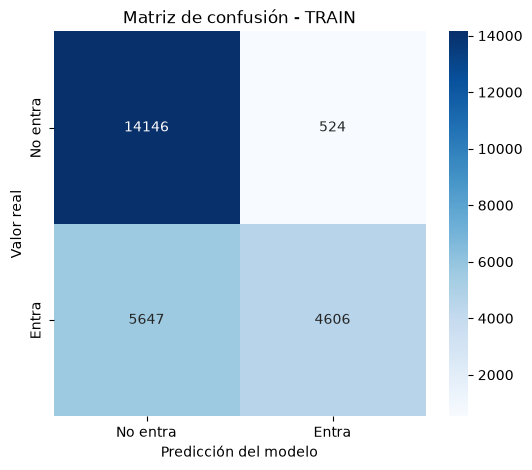

In [ ]:
probabilidades = rf_final.predict(X_test).flatten()

predicciones = (probabilidades >= 0.5).astype(int)

matriz = confusion_matrix(y_test, predicciones)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No entra", "Entra"],
    yticklabels=["No entra", "Entra"]
)

plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - TEST")

plt.show()

## Guardar modelo

In [ ]:
joblib.dump(rf_final, "../model/modelo_random_forest.pkl")

['../model/modelo_random_forest.pkl']

## Evaluación del modelo

Tras entrenar y evaluar el modelo Random Forest, se han obtenido resultados limitados, destacando especialmente su F1-score de validación de 0.390 y su recall de 0.271.

El recall es uno de los aspectos más importantes en este problema, ya que indica que el modelo consigue identificar aproximadamente el 27,1 % de las canciones que realmente alcanzan el Top 30 de Billboard. Esto significa que deja sin detectar alrededor del 72,9 % de las canciones exitosas. Desde el punto de vista empresarial, este comportamiento supone una limitación importante, puesto que la discográfica podría descartar numerosas canciones con potencial comercial.

Por otra parte, el F1-score de validación de 0.390 refleja un equilibrio reducido entre precisión y recall. Además, el ROC-AUC de 0.675 indica que el modelo tiene cierta capacidad para distinguir entre las canciones que alcanzan el Top 30 y las que no, aunque su rendimiento todavía es mejorable.

Un aspecto que llama especialmente la atención es la diferencia entre el F1-score de entrenamiento (0.636) y el de validación (0.390). Esta diferencia puede indicar que el modelo está sufriendo sobreajuste (*overfitting*), es decir, aprende patrones específicos de los datos de entrenamiento que no consigue generalizar correctamente a canciones que no ha visto anteriormente.

En comparación con XGBoost, Random Forest presenta un recall de validación considerablemente inferior (0.271 frente a 0.697), por lo que identifica una proporción mucho menor de las canciones que realmente alcanzan el Top 30. Aunque su ROC-AUC de 0.675 es ligeramente superior al de XGBoost (0.646), esto no se traduce en una mejor capacidad de detección utilizando el umbral de clasificación actual.

En conclusión, considero que Random Forest presenta limitaciones importantes para el problema planteado, especialmente por su bajo recall y la diferencia entre los resultados de entrenamiento y validación. Aunque consigue aprender patrones de los datos, parece tener dificultades para generalizarlos. Por tanto, no lo seleccionaría como modelo definitivo sin realizar antes ajustes en sus hiperparámetros, como limitar la profundidad de los árboles o modificar el número mínimo de muestras necesarias para dividir un nodo.

Finalmente, mantendría este modelo dentro de la comparación realizada, ya que permite comprobar que una mayor complejidad no garantiza necesariamente mejores resultados y que es fundamental valorar la capacidad de generalización y las métricas más relacionadas con el objetivo empresarial.